# Intro to Computational Science
# Assignment 2
Timothy Böhm - 17068061

Lydia Shumskaya - 14212781

# Problem 1

1.1: Implementing of Gillespies Direct Method Algorithm

There are 6 events:
 - Birth
 - Infection
 - Recovery
 - Susceptible death
 - Infected death
 - Recovered death

 Drawing of these events is of exponential time of the sum of their rates.

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def gillespie_sir(y, beta, gamma, mu, t_max, seed=None):
    rng = np.random.default_rng(seed)

    S, I, R = y
    t = 0.0

    times = [t]
    S_values = [S]
    I_values = [I]
    R_values = [R]

    while t < t_max:
        N = S + I + R

        if N == 0:
            break

        # Rates of the six possible events
        rates = np.array([
            mu * N,           # Birth
            beta * S * I / N, # Infection
            gamma * I,        # Recovery
            mu * S,           # Susceptible death
            mu * I,           # Infected death
            mu * R            # Recovered death
        ])

        total_rate = np.sum(rates)

        if total_rate == 0:
            break

        # Time until the next event
        dt = rng.exponential(1 / total_rate)

        if t + dt > t_max:
            break

        t += dt

        # Choose which event occurs
        event = rng.choice(len(rates), p=rates / total_rate)

        if event == 0:
            S += 1
        elif event == 1:
            S -= 1
            I += 1
        elif event == 2:
            I -= 1
            R += 1
        elif event == 3:
            S -= 1
        elif event == 4:
            I -= 1
        elif event == 5:
            R -= 1

        # Record the updated state
        times.append(t)
        S_values.append(S)
        I_values.append(I)
        R_values.append(R)

    return [np.array(times), np.array(S_values), np.array(I_values), np.array(R_values)]

In [18]:
from scipy.integrate import odeint
import numpy as np
import matplotlib.pyplot as plt

def sir_demography(y, t, beta, gamma, mu):
    S, I, R = y
    N = S + I + R

    dSdt = mu*N - beta*S*I/N - mu*S
    dIdt = beta*S*I/N - gamma*I - mu*I
    dRdt = gamma*I - mu*R

    return [dSdt, dIdt, dRdt]

In [19]:
# Initial conditions
S0 = 990
I0 = 10
R0 = 0

# Parameters
beta = 0.3
gamma = 0.1
mu = 0.01
t_max = 200

# Deterministic SIR
t = np.linspace(0, t_max, 2000)

sol = odeint(
    sir_demography,
    [S0, I0, R0],
    t,
    args=(beta, gamma, mu)
)

S_det, I_det, R_det = sol.T

# Stochastic SIR using Gillespie
solution = gillespie_sir(
    [S0, I0, R0],
    beta, gamma, mu,
    t_max,
    seed=42
)
t_stoch, S_stoch, I_stoch, R_stoch = solution

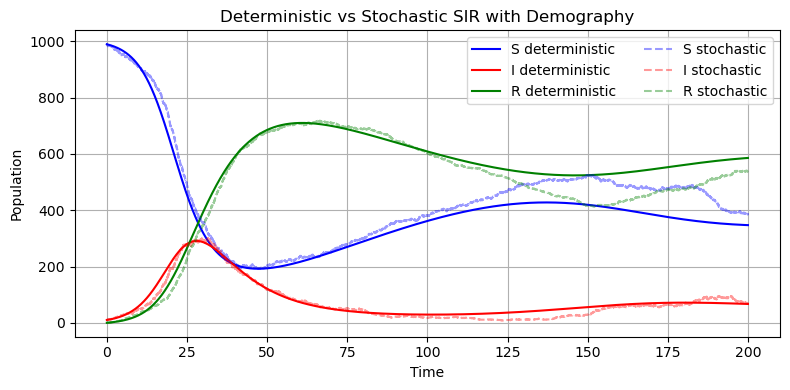

In [20]:
plt.figure(figsize=(8, 4))

# Deterministic model
plt.plot(t, S_det, color="blue", label="S deterministic")
plt.plot(t, I_det, color="red", label="I deterministic")
plt.plot(t, R_det, color="green", label="R deterministic")

# Stochastic model
plt.step(t_stoch, S_stoch, where="post",
         color="blue", alpha=0.4, linestyle="--",
         label="S stochastic")

plt.step(t_stoch, I_stoch, where="post",
         color="red", alpha=0.4, linestyle="--",
         label="I stochastic")

plt.step(t_stoch, R_stoch, where="post",
         color="green", alpha=0.4, linestyle="--",
         label="R stochastic")

plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Deterministic vs Stochastic SIR with Demography")

plt.legend(ncol=2)
plt.grid()
plt.tight_layout()
plt.show()

1.2: Investigate Simulation Variability and Negative Co-variance

Covariance shows whether two variables tend to increase of decrease together.

For infected and susceptible populations it is:

$\operatorname{Cov}(S,I)=E[(S-E[S])(I-E[I])]$

We will run 100 stochastic simulations to find the results.

In [21]:
def run_stochastic(y0, beta, gamma, mu, t_common, n_runs=100):
    S_runs = []
    I_runs = []

    for seed in range(n_runs):
        times, S, I, R = gillespie_sir(
            y0, beta, gamma, mu, t_common[-1], seed=seed
        )

        indices = np.searchsorted(times, t_common, side="right") - 1

        S_runs.append(S[indices])
        I_runs.append(I[indices])

    return np.array(S_runs), np.array(I_runs)

In [22]:
# Same params as before
y0 = [990, 10, 0]

beta = 0.3
gamma = 0.1
mu = 0.01

t_max = 200
n_runs = 100

t_common = np.linspace(0, t_max, 1000)

S_runs = []
I_runs = []

for seed in range(n_runs):
    times, S, I, R = gillespie_sir(
        y0, beta, gamma, mu, t_max, seed=seed
    )

    # Get the most recent event before each time point
    indices = np.searchsorted(times, t_common, side="right") - 1

    S_runs.append(S[indices])
    I_runs.append(I[indices])

S_runs = np.array(S_runs)
I_runs = np.array(I_runs)

# Calculate the mean and covariance of S and I across runs
S_mean = np.mean(S_runs, axis=0)
I_mean = np.mean(I_runs, axis=0)

cov_SI = np.mean(
    (S_runs - S_mean) * (I_runs - I_mean),
    axis=0
)

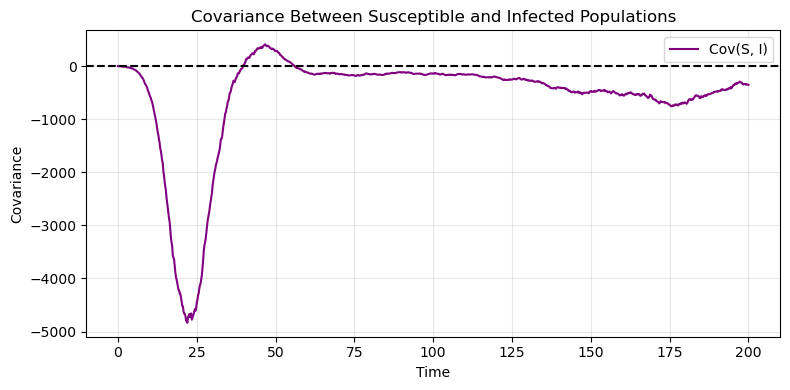

In [23]:
plt.figure(figsize=(8, 4))

plt.plot(t_common, cov_SI, color="purple",
         label="Cov(S, I)")

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Time")
plt.ylabel("Covariance")
plt.title("Covariance Between Susceptible and Infected Populations")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

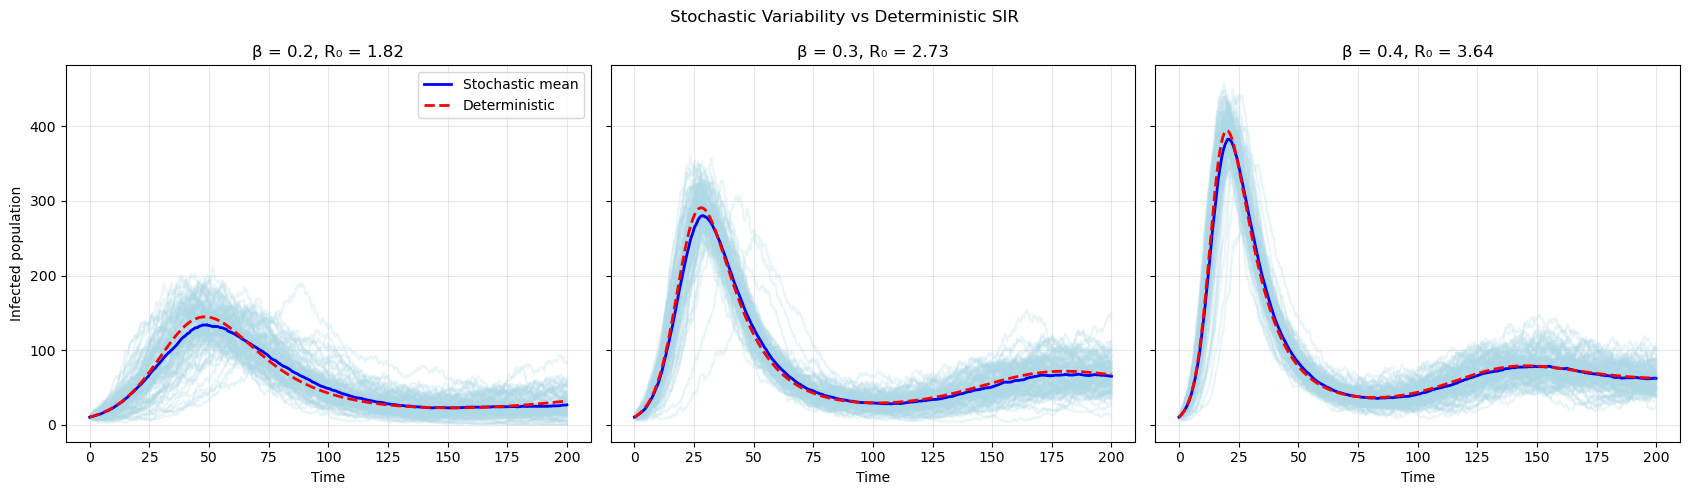

In [24]:
y0 = [990, 10, 0]
gamma = 0.1
mu = 0.01

betas = [0.2, 0.3, 0.4]
t_common = np.linspace(0, 200, 1000)
n_runs = 100

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)

results = {}

for ax, beta in zip(axes, betas):

    S_runs, I_runs = run_stochastic(
        y0, beta, gamma, mu, t_common, n_runs
    )

    results[beta] = (S_runs, I_runs)

    I_mean = np.mean(I_runs, axis=0)

    # Deterministic solution
    sol = odeint(
        sir_demography, y0, t_common,
        args=(beta, gamma, mu)
    )
    I_det = sol[:, 1]

    # Individual stochastic simulations
    for I_run in I_runs:
        ax.plot(t_common, I_run, color="lightblue", alpha=0.25)

    # Mean stochastic trajectory
    ax.plot(t_common, I_mean, color="blue",
            linewidth=2, label="Stochastic mean")

    # Deterministic trajectory
    ax.plot(t_common, I_det, color="red",
            linewidth=2, linestyle="--", label="Deterministic")

    ax.set_title(f"β = {beta}, R₀ = {beta/(gamma+mu):.2f}")
    ax.set_xlabel("Time")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Infected population")
axes[0].legend()

plt.suptitle("Stochastic Variability vs Deterministic SIR")
plt.tight_layout()
plt.show()

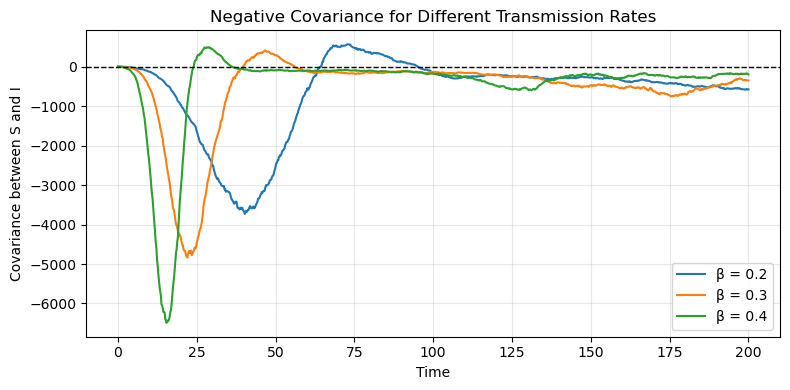

In [25]:
plt.figure(figsize=(8, 4))

for beta in betas:
    S_runs, I_runs = results[beta]

    S_mean = np.mean(S_runs, axis=0)
    I_mean = np.mean(I_runs, axis=0)

    covariance = np.mean(
        (S_runs - S_mean) * (I_runs - I_mean),
        axis=0
    )

    plt.plot(t_common, covariance,
             label=f"β = {beta}")

plt.axhline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("Time")
plt.ylabel("Covariance between S and I")
plt.title("Negative Covariance for Different Transmission Rates")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1.3 Stochastic Resonance and Increased Transien

For deterministic SIR model with demography, the endemic points are:


$S^*=N\frac{\gamma+\mu}{\beta}$



$I^*=\frac{\mu}{\gamma+\mu}(N-S^*)$



$R^*=\frac{\gamma}{\mu}I^*$


In [26]:
def endemic_equilibrium(N, beta, gamma, mu):
    S = N * (gamma + mu) / beta
    I = mu * (N - S) / (gamma + mu)
    R = gamma * I / mu

    return np.array([S, I, R])

We will analyse the transient level for different population sizes. We will compare 200,1000,2000 and 10000.

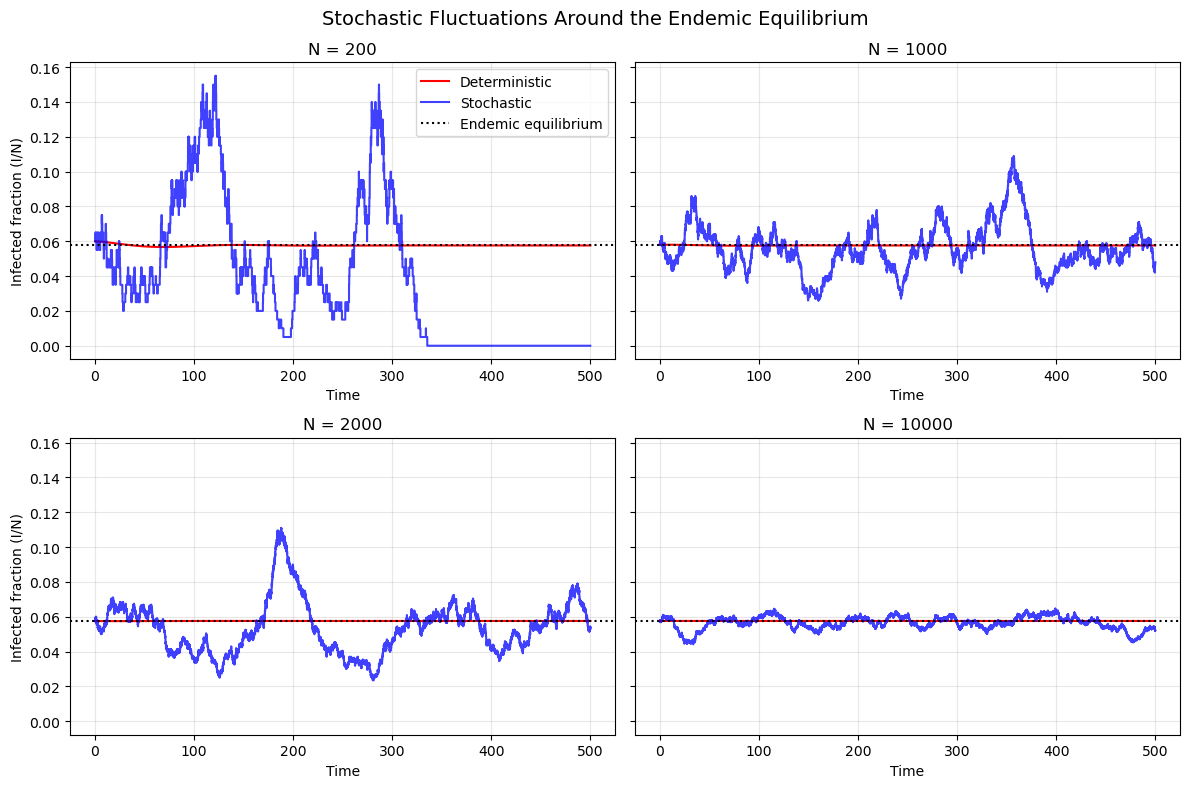

In [27]:
beta = 0.3
gamma = 0.1
mu = 0.01

populations = [200, 1000, 2000,10000]
t_max = 500
t = np.linspace(0, t_max, 2000)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

for ax, N in zip(axes.flat, populations):

    equilibrium = endemic_equilibrium(N, beta, gamma, mu)

    S0 = round(equilibrium[0])
    I0 = round(equilibrium[1])
    R0 = N - S0 - I0
    y0 = [S0, I0, R0]

    # Deterministic model
    sol = odeint(sir_demography, y0, t, args=(beta, gamma, mu))

    # Stochastic model
    times, S, I, R = gillespie_sir(
        y0, beta, gamma, mu, t_max, seed=42
    )

    ax.plot(t, sol[:, 1] / N,
            color="red", label="Deterministic")

    ax.step(times, I / N, where="post",
            color="blue", alpha=0.75, label="Stochastic")

    ax.axhline(equilibrium[1] / N,
               color="black", linestyle=":",
               label="Endemic equilibrium")

    ax.set_title(f"N = {N}")
    ax.set_xlabel("Time")
    ax.grid(alpha=0.3)

axes[0, 0].set_ylabel("Infected fraction (I/N)")
axes[1, 0].set_ylabel("Infected fraction (I/N)")
axes[0, 0].legend()

plt.suptitle("Stochastic Fluctuations Around the Endemic Equilibrium", fontsize=14)
plt.tight_layout()
plt.show()

We can quanity the size of the transients.
We do this by calculating the mean squared deviations from the deterministic endemic equilibrium, larger value of D means that the trajectory deviates more from the equilibrium.

$
D=\sqrt{\frac{1}{T}\int_0^T
\left(\frac{I(t)}{N}-\frac{I^*}{N}\right)^2dt}
$

In [28]:
n_runs = 30
t_common = np.linspace(0, t_max, 2000)

for N in populations:
    equilibrium = endemic_equilibrium(N, beta, gamma, mu)

    S0 = round(equilibrium[0])
    I0 = round(equilibrium[1])
    R0 = N - S0 - I0
    y0 = [S0, I0, R0]

    deviations = []

    for seed in range(n_runs):
        times, S, I, R = gillespie_sir(
            y0, beta, gamma, mu, t_max, seed=seed
        )

        indices = np.searchsorted(times, t_common, side="right") - 1
        I_fraction = I[indices] / N

        deviation = np.sqrt(
            np.mean((I_fraction - equilibrium[1] / N)**2)
        )

        deviations.append(deviation)

    print(f"N = {N}: mean RMS deviation = {np.mean(deviations):.4f}")

N = 200: mean RMS deviation = 0.0468
N = 1000: mean RMS deviation = 0.0176
N = 2000: mean RMS deviation = 0.0130
N = 10000: mean RMS deviation = 0.0053


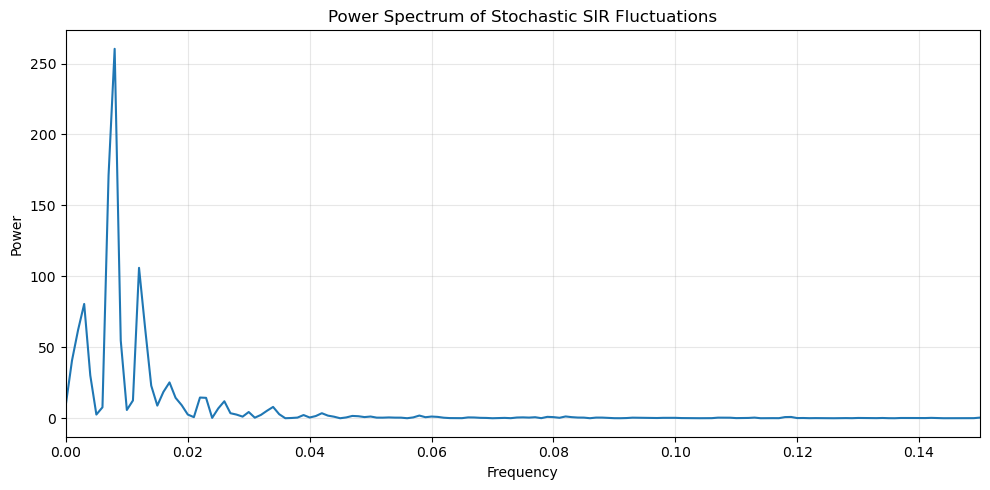

In [29]:
N = 1000
t_max = 1000
dt = 0.2

t_common = np.arange(0, t_max, dt)

equilibrium = endemic_equilibrium(N, beta, gamma, mu)

S0 = round(equilibrium[0])
I0 = round(equilibrium[1])
R0 = N - S0 - I0

y0 = [S0, I0, R0]

times, S, I, R = gillespie_sir(
    y0, beta, gamma, mu, t_max, seed=42
)

indices = np.searchsorted(times, t_common, side="right") - 1
I_uniform = I[indices] / N

# Remove the mean
signal = I_uniform - np.mean(I_uniform)

# Apply a Hann window
window = np.hanning(len(signal))
signal_windowed = signal * window

# Fourier transform
fft_values = np.fft.rfft(signal_windowed)
frequencies = np.fft.rfftfreq(len(signal), d=dt)

power = np.abs(fft_values)**2

plt.figure(figsize=(10, 5))

plt.plot(frequencies, power)
plt.xlim(0, 0.15)

plt.xlabel("Frequency")
plt.ylabel("Power")
plt.title("Power Spectrum of Stochastic SIR Fluctuations")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1.4: Extinction events and Critical Community Size

Stochastic extinction can occur in a population even when R_0 > 1. We tart from the theoretical equilibirum points, perform 100 runs per population size up to t=500. Then count how many exctinction there have been to find the propability of an extinction before t = 500. 

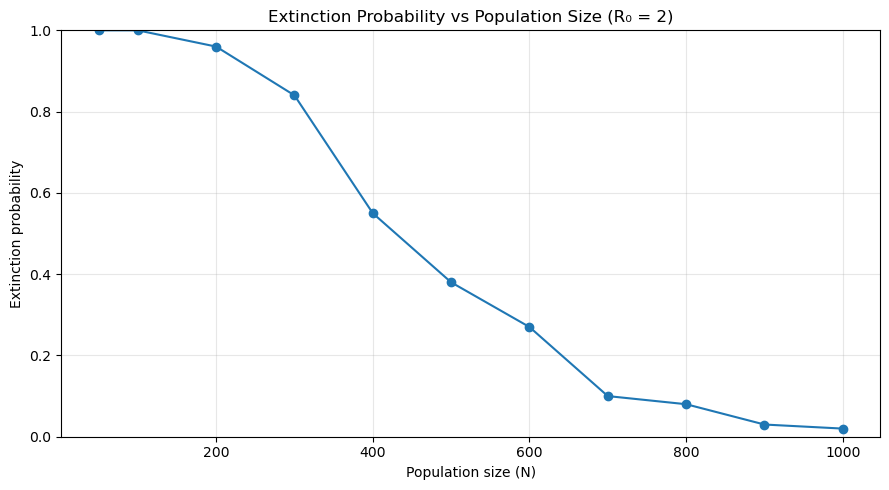

In [30]:
gamma = 0.1
mu = 0.01

R_nought = 2
beta = R_nought * (gamma + mu)

populations = [50, 100, 200, 300,400, 500,600,700,800,900, 1000]
n_runs = 100
t_max = 500

extinction_probabilities = []

for N in populations:
    equilibrium = endemic_equilibrium(N, beta, gamma, mu)

    S0 = round(equilibrium[0])
    I0 = max(1, round(equilibrium[1]))
    R0 = N - S0 - I0
    y0 = [S0, I0, R0]

    extinctions = 0

    for seed in range(n_runs):
        times, S, I, R = gillespie_sir(
            y0, beta, gamma, mu, t_max, seed=seed
        )

        if np.any(I == 0):
            extinctions += 1

    extinction_probabilities.append(extinctions / n_runs)

plt.figure(figsize=(9, 5))
plt.plot(populations, extinction_probabilities, marker="o")

plt.xlabel("Population size (N)")
plt.ylabel("Extinction probability")
plt.title(f"Extinction Probability vs Population Size (R₀ = {R_nought})")

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Now we test the interaction between population size and reproduction number.

In [31]:
populations = [100, 200,300,400, 500,600,700,800,900, 1000]
R_nought_values = [1.2, 1.5,1.75, 2,2.5, 3,3.5, 4,4.5, 5]

n_runs = 20
t_max = 500

extinction_matrix = np.zeros(
    (len(R_nought_values), len(populations))
)

for i, R_nought in enumerate(R_nought_values):
    beta = R_nought * (gamma + mu)

    for j, N in enumerate(populations):
        equilibrium = endemic_equilibrium(N, beta, gamma, mu)

        S0 = round(equilibrium[0])
        I0 = max(1, round(equilibrium[1]))
        R0 = N - S0 - I0
        y0 = [S0, I0, R0]

        extinctions = 0

        for seed in range(n_runs):
            times, S, I, R = gillespie_sir(
                y0, beta, gamma, mu, t_max, seed=seed
            )

            if np.any(I == 0):
                extinctions += 1

        extinction_matrix[i, j] = extinctions / n_runs

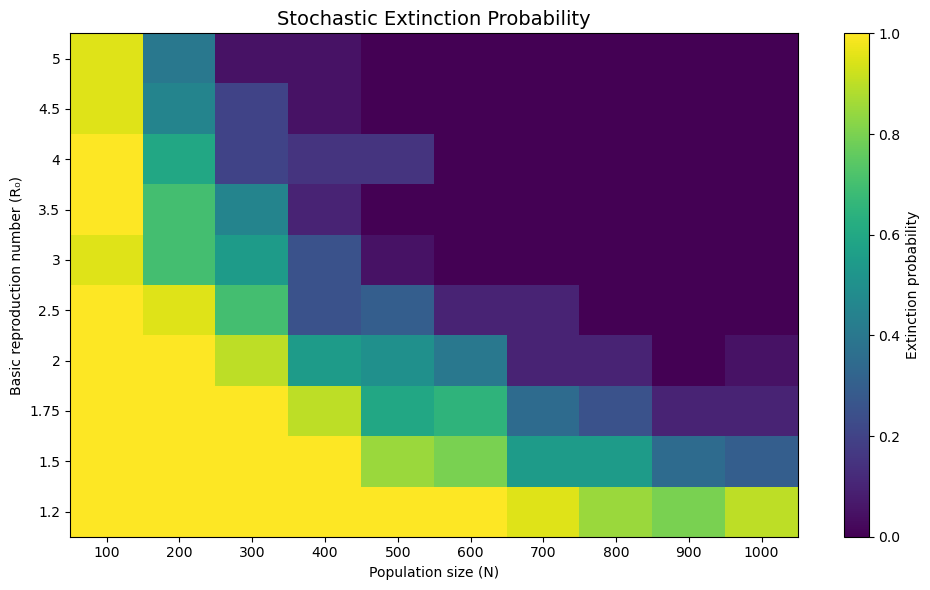

In [32]:
plt.figure(figsize=(10, 6))

plt.imshow(
    extinction_matrix,
    origin="lower",
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Extinction probability")

plt.xticks(range(len(populations)), populations)
plt.yticks(range(len(R_nought_values)), R_nought_values)

plt.xlabel("Population size (N)")
plt.ylabel("Basic reproduction number (R₀)")
plt.title("Stochastic Extinction Probability", fontsize=14)

plt.tight_layout()
plt.show()

In [33]:
for i, R_nought in enumerate(R_nought_values):
    persistence = 1 - extinction_matrix[i]

    suitable = np.where(persistence >= 0.95)[0]

    if len(suitable) > 0:
        N_critical = populations[suitable[0]]
        print(f"R₀ = {R_nought}: estimated CCS ≤ {N_critical}")
    else:
        print(f"R₀ = {R_nought}: CCS exceeds tested population range")

R₀ = 1.2: CCS exceeds tested population range
R₀ = 1.5: CCS exceeds tested population range
R₀ = 1.75: CCS exceeds tested population range
R₀ = 2: estimated CCS ≤ 900
R₀ = 2.5: estimated CCS ≤ 800
R₀ = 3: estimated CCS ≤ 500
R₀ = 3.5: estimated CCS ≤ 500
R₀ = 4: estimated CCS ≤ 600
R₀ = 4.5: estimated CCS ≤ 400
R₀ = 5: estimated CCS ≤ 300


Problem 2: Spatial Models - Networks 


Erdos Renyi graph specifies number of nodes and $p$ probability that any pair of nodes is connected. $\bar{k} = p(n - 1)$. 

Watts-Strogatz graph specifies number of nodes and each node connects to approximately $k$ neigbours, each edge has a rewiring probabilty of $p$. 

Barabasi-Albert specifies number of nodes. Every node that enters the network creates $m$ edges to existing nodes. $\bar{k} = 2m$. 

!!Do we want to do statistical testing to see if theyre actually similar?!!


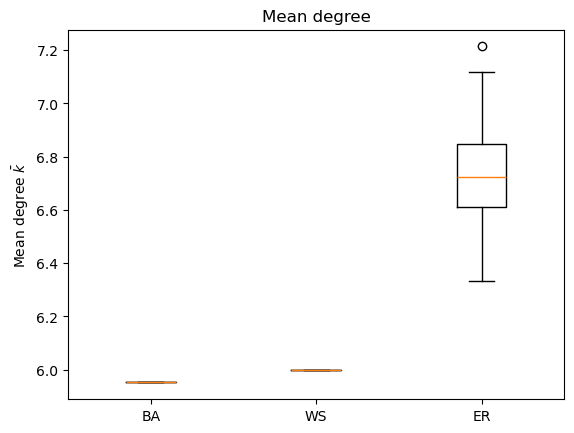

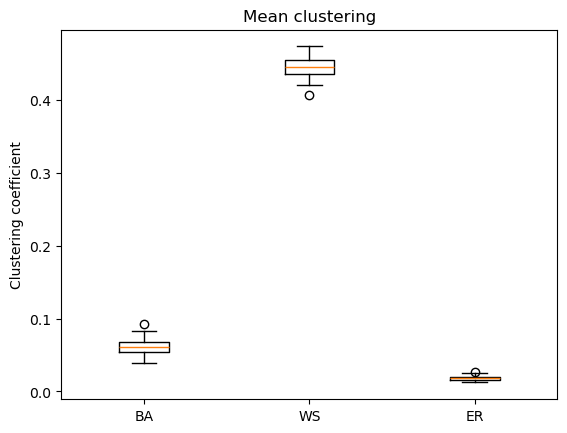

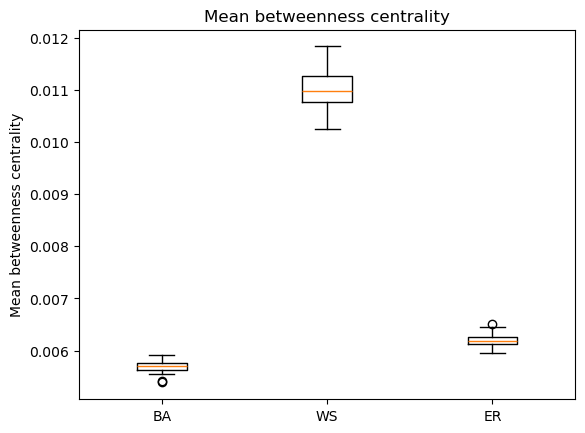

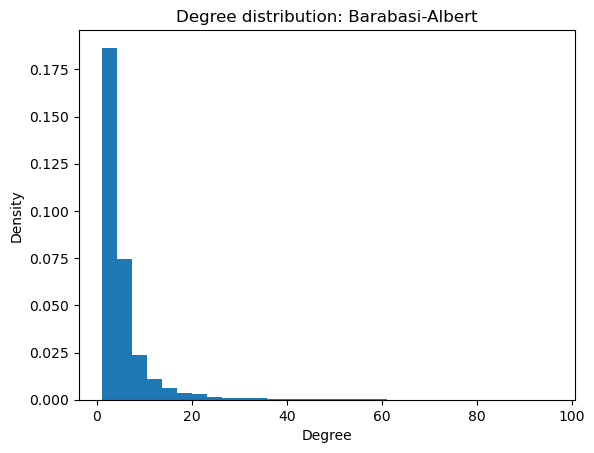

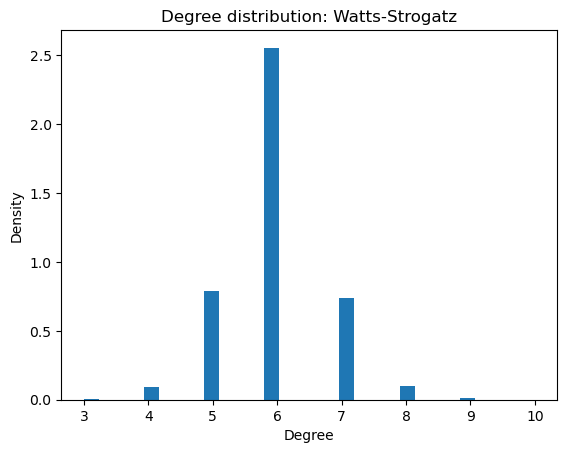

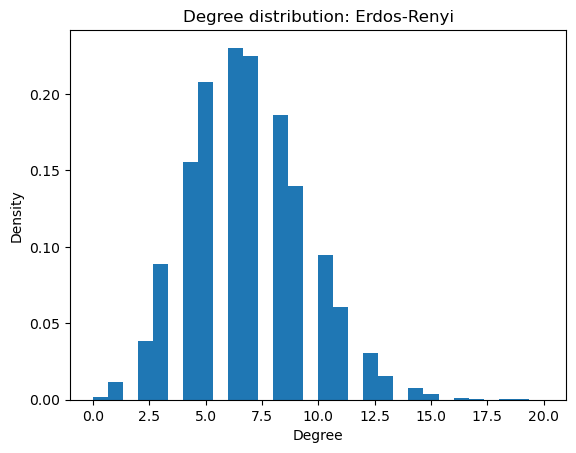

In [34]:
import networkx as nx
import ndlib.models.epidemics as ep
import ndlib.models.ModelConfig as mc
import numpy as np 
import matplotlib.pyplot as plt

#number of nodes
n = 374 

#number of runs 
runs = 100 

#making lists that store network results 
mean_degree = {'BA': [], 'WS': [], 'ER': []}
mean_clustering = {'BA': [], 'WS': [], 'ER': []}
mean_betweenness = {'BA': [], 'WS': [], 'ER': []}
degree_distribution = {'BA': [], 'WS': [], 'ER': []}

for i in range(runs):
    #defining networks with similar properties (374 nodes and a degree between 6 and 7)
    g_ba = nx.barabasi_albert_graph(n = n, m = 3, seed = i)
    g_ws = nx.watts_strogatz_graph(n = n, k = 6, p = 0.1, seed = i)
    g_er = nx.erdos_renyi_graph(n = n, p = 0.018, seed = i)

    network = {'BA': g_ba, 'WS': g_ws, 'ER': g_er}
    
    #get statistics from each network 
    for name, g in network.items():
        degrees = [degree for node, degree in g.degree]
        mean_degree[name].append(np.mean(degrees))
        mean_clustering[name].append(nx.average_clustering(g))
        degree_distribution[name].extend(degrees)
        betweenness = nx.betweenness_centrality(g)
        betweenness_values = list(betweenness.values())
        mean_betweenness[name].append(np.mean(betweenness_values))

#plotting
#mean degree 
network_names = ['BA', 'WS', 'ER']

plt.boxplot([mean_degree['BA'], mean_degree['WS'], mean_degree['ER']],tick_labels=network_names)
plt.title('Mean degree')
plt.ylabel(r'Mean degree $\bar{k}$')
plt.show()


#mean clustering 
plt.boxplot([mean_clustering['BA'], mean_clustering['WS'], mean_clustering['ER']], tick_labels=network_names)
plt.title('Mean clustering')
plt.ylabel('Clustering coefficient')
plt.show()

#mean betweenness
plt.boxplot([mean_betweenness['BA'], mean_betweenness['WS'], mean_betweenness['ER']], tick_labels=network_names)
plt.title('Mean betweenness centrality')
plt.ylabel('Mean betweenness centrality')
plt.show()

#degree distribution BA
plt.hist(degree_distribution['BA'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Barabasi-Albert')
plt.show()

#degree distribution WS
plt.hist(degree_distribution['WS'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Watts-Strogatz')
plt.show()

#degree distribution ER
plt.hist(degree_distribution['ER'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Erdos-Renyi')
plt.show()

Simulating SIR spread on networks 

Simulating with varying fraction of initial infected, which nodes are initially infected and $\beta$

In [35]:
import ndlib.models.ModelConfig as mc

initial_infected_fractions = [0.01, 0.05, 0.10]
beta = 0.05
gamma = 0.1
nruns = 100
results_changing_fractions = {}

#generating different network types with similar properties 
g_ba = nx.barabasi_albert_graph(n = n, m = 3, seed = 0)
g_ws = nx.watts_strogatz_graph(n = n, k = 6, p = 0.1, seed = 0)
g_er = nx.erdos_renyi_graph(n = n, p = 0.018, seed = 0)
network = {'BA': g_ba, 'WS': g_ws, 'ER': g_er}

#function that runs one SIR simulation 
def run_sir(g, beta, gamma, iterations = 100, fraction_infected = 0.05, infected_nodes = None, seed = None):

    #specify model 
    model = ep.SIRModel(g, seed=seed)

    #model configuration 
    config = mc.Configuration()
    config.add_model_parameter('beta', beta)
    config.add_model_parameter('gamma', gamma)
    config.add_model_parameter('fraction_infected', fraction_infected)
    if infected_nodes is not None:
        config.add_model_initial_configuration('Infected', infected_nodes)
    model.set_initial_status(config)

    # Run simulation
    output = model.iteration_bunch(iterations)

    #collecting states of each node 
    S = [step['node_count'][0] for step in output]
    I = [step['node_count'][1] for step in output]
    R = [step['node_count'][2] for step in output]

    return np.array(S), np.array(I), np.array(R)

#function that repeats stochastic SIR model  
def repeat_sir(g, beta, gamma, runs = nruns, fraction_infected = 0.05, infected_nodes=None):
    S_runs = []
    I_runs = []
    R_runs = []

    for i in range(runs):

        S, I, R = run_sir(g, beta, gamma, fraction_infected = fraction_infected, infected_nodes = infected_nodes, seed = i)
        S_runs.append(S)
        I_runs.append(I)
        R_runs.append(R)
    return (np.array(S_runs), np.array(I_runs), np.array(R_runs))



Varying fractions initially infected in different network types

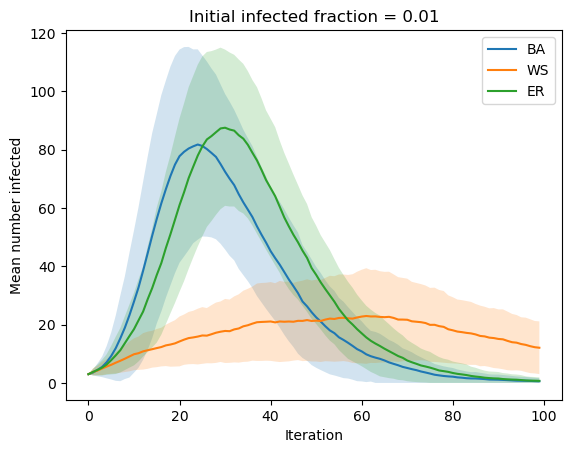

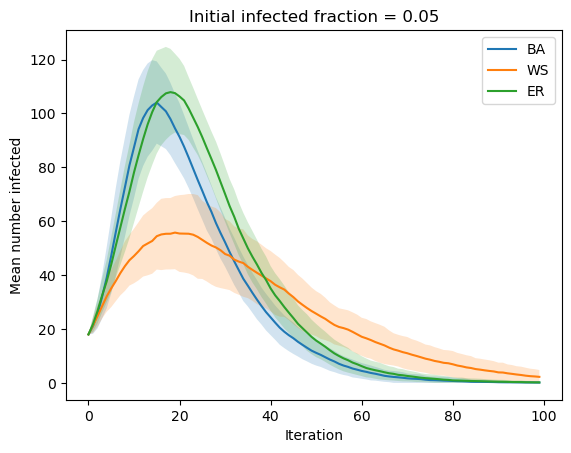

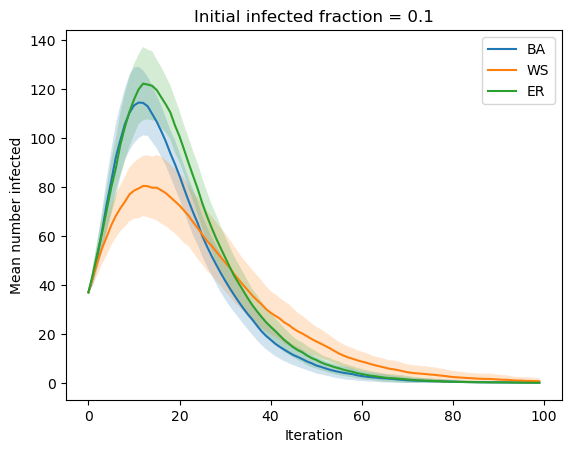

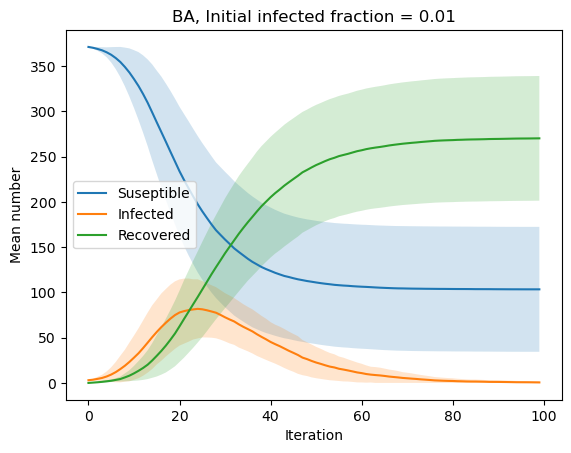

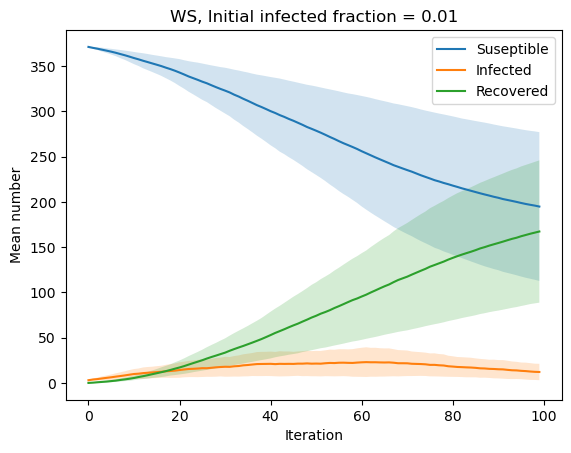

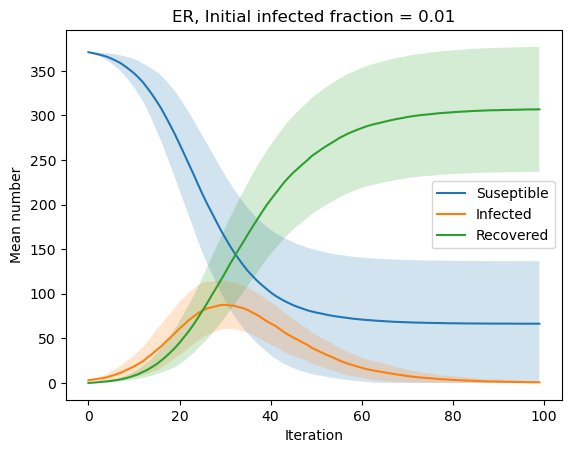

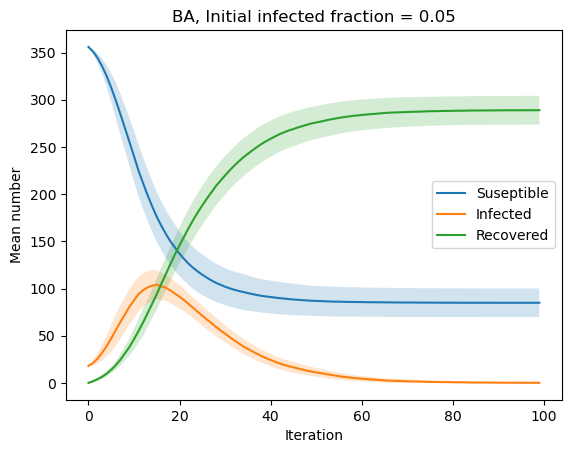

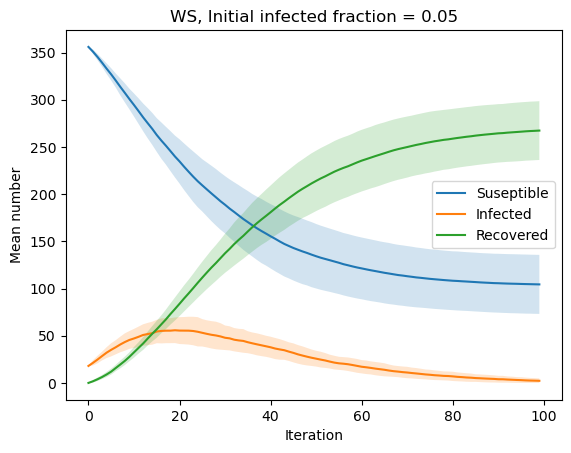

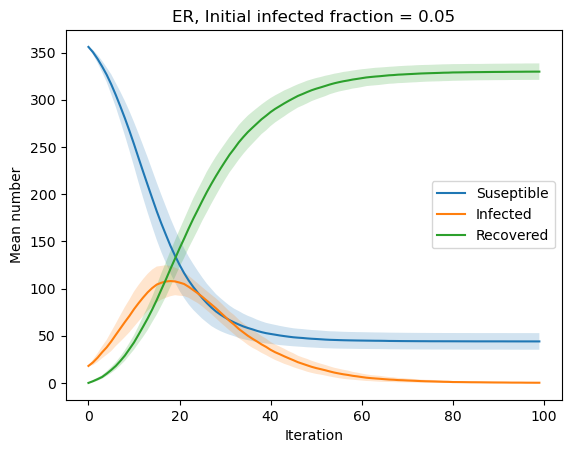

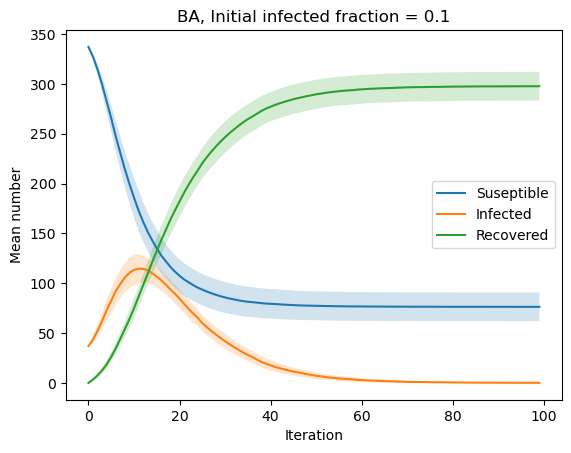

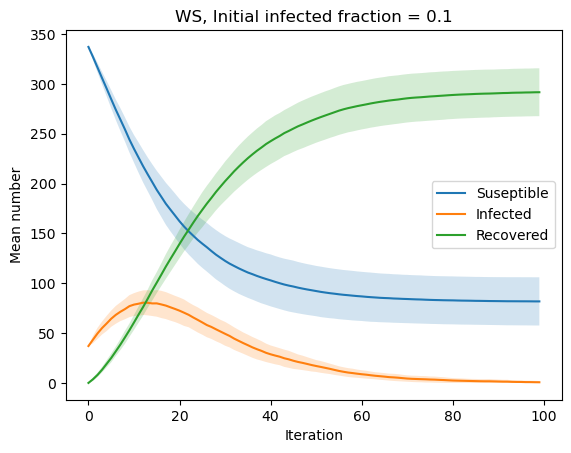

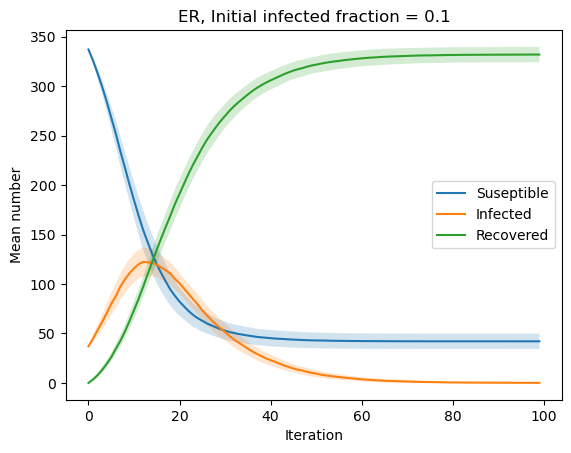

In [36]:
initial_infected_fractions = [0.01, 0.05, 0.10]
beta = 0.05
gamma = 0.1
nruns = 100
results_changing_fractions = {}

for fraction in initial_infected_fractions:
    results_changing_fractions[fraction] = {}
    for name, g in network.items():
        S_runs, I_runs, R_runs = repeat_sir(g, beta, gamma, runs = nruns, fraction_infected = fraction)
        results_changing_fractions[fraction][name] = {'S' : S_runs, 'I' : I_runs, 'R' : R_runs}

#plotting mean number infected  
for fraction in initial_infected_fractions:
    for name in network:
        I_runs = results_changing_fractions[fraction][name]['I']
        mean_I = np.mean(I_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        plt.plot(mean_I, label = name)
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number infected')
    plt.title(f'Initial infected fraction = {fraction}')
    plt.legend()
    plt.show()

#plotting SIR
for fraction in initial_infected_fractions:
    for name in network:
        S_runs = results_changing_fractions[fraction][name]['S']
        I_runs = results_changing_fractions[fraction][name]['I']
        R_runs = results_changing_fractions[fraction][name]['R']
        mean_S = np.mean(S_runs, axis=0)
        mean_I = np.mean(I_runs, axis=0)
        mean_R = np.mean(R_runs, axis=0)
        std_S = np.std(S_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        std_R = np.std(R_runs, axis=0)
        plt.plot(mean_S, label = 'Suseptible')
        plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
        plt.plot(mean_I, label = 'Infected')
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
        plt.plot(mean_R, label = 'Recovered')
        plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
        plt.xlabel('Iteration')
        plt.ylabel('Mean number')
        plt.title(f'{name}, Initial infected fraction = {fraction}')
        plt.legend()
        plt.show()


Simulating with varying which nodes are infected

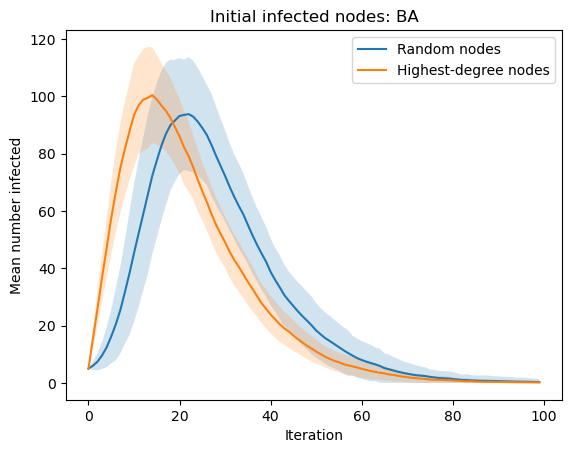

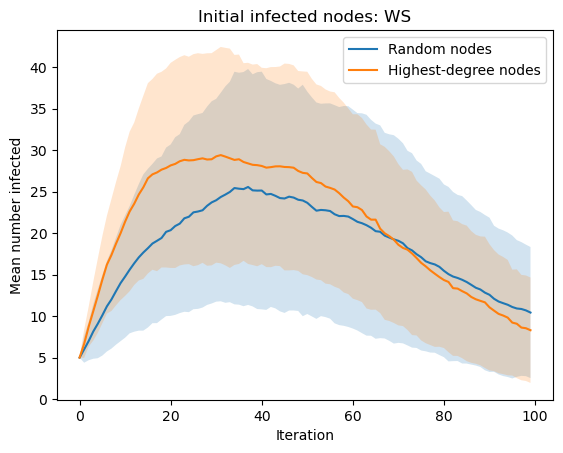

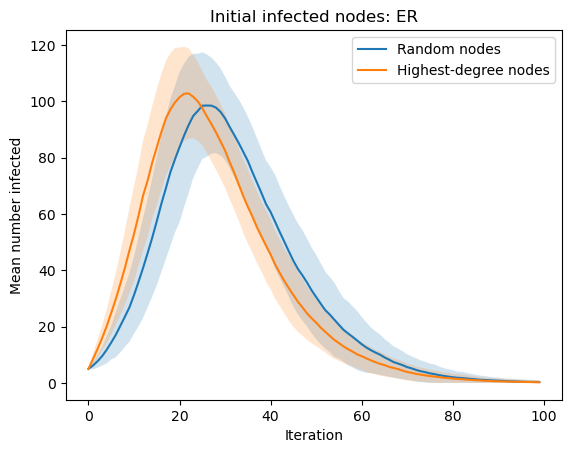

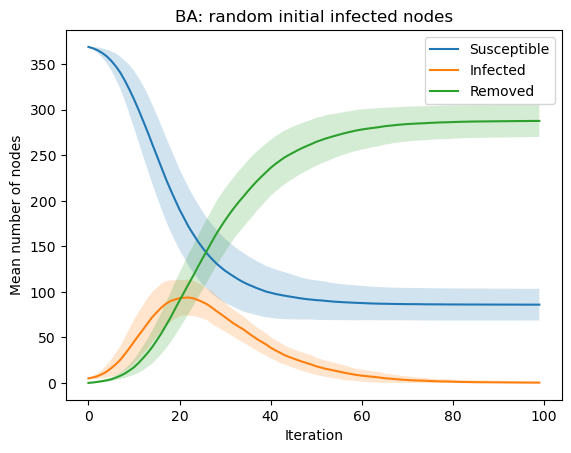

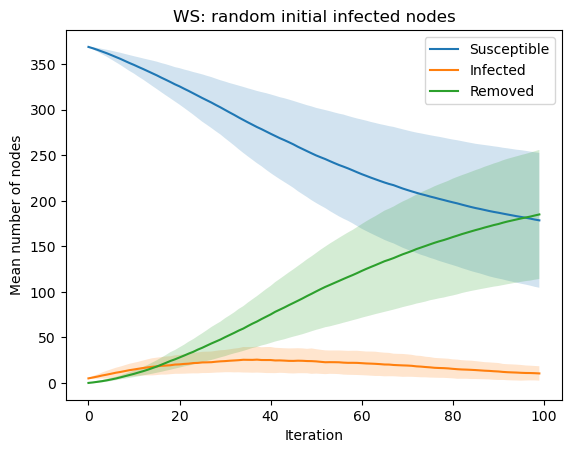

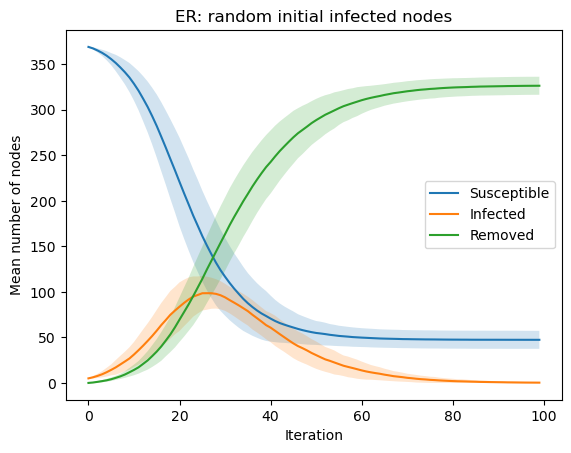

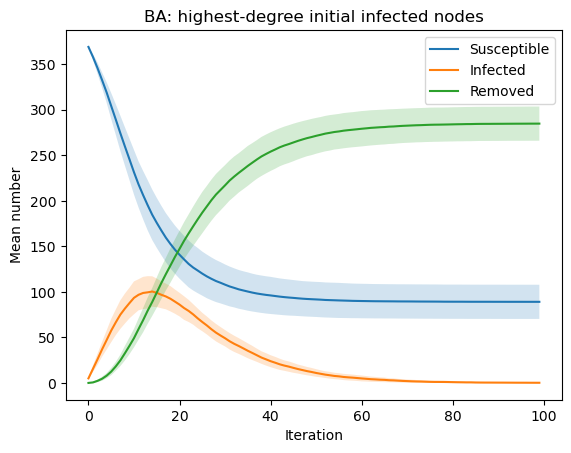

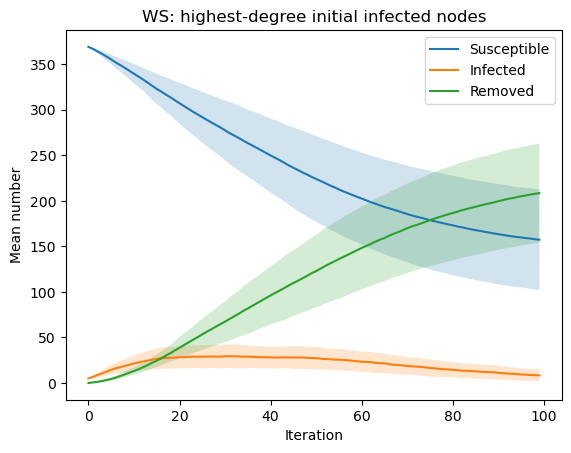

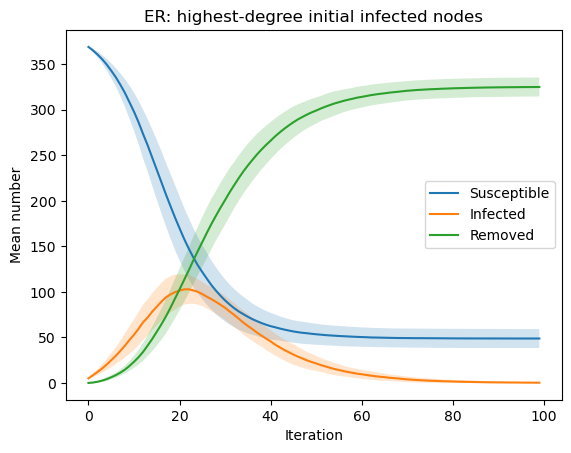

In [37]:
beta = 0.05
gamma = 0.1
nruns = 100
number_infected = 5
results_nodes = {}

for name, g in network.items():

    results_nodes[name] = {'random': {'S' : [], 'I' : [], 'R' : []}, 'high_degree': {'S' : [], 'I': [], 'R': []}}

    #getting the highest degree nodes
    highest_degree = sorted(g.degree, key = lambda x: x[1], reverse = True)[:number_infected]
    highest_degree_nodes = [node for node, degree in highest_degree]

    for i in range(nruns):
        #generating random nodes 
        rng = np.random.default_rng(i)
        random_nodes = rng.choice(list(g.nodes()), size = number_infected, replace = False).tolist()

        S, I, R = run_sir(g, beta, gamma, infected_nodes = random_nodes, seed = i)
        results_nodes[name]['random']['S'].append(S)
        results_nodes[name]['random']['I'].append(I)
        results_nodes[name]['random']['R'].append(R)

        S, I, R = run_sir(g, beta, gamma, infected_nodes = highest_degree_nodes, seed = i)
        results_nodes[name]['high_degree']['S'].append(S)
        results_nodes[name]['high_degree']['I'].append(I)
        results_nodes[name]['high_degree']['R'].append(R)

#plotting mean infected 
for name in network:
    random_runs = np.array(results_nodes[name]['random']['I'])
    high_degree_runs = np.array(results_nodes[name]['high_degree']['I'])

    mean_random = np.mean(random_runs, axis = 0)
    std_random = np.std(random_runs, axis = 0)
    mean_high_degree = np.mean(high_degree_runs, axis=0)
    std_high_degree = np.std(high_degree_runs, axis=0)
    plt.plot(mean_random, label='Random nodes')
    plt.fill_between(np.arange(len(mean_random)), np.maximum(mean_random - std_random, 0), mean_random + std_random, alpha=0.2)
    plt.plot(mean_high_degree, label='Highest-degree nodes')
    plt.fill_between(np.arange(len(mean_high_degree)), np.maximum(mean_high_degree - std_high_degree, 0), mean_high_degree + std_high_degree, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number infected')
    plt.title(f'Initial infected nodes: {name}')
    plt.legend()
    plt.show()

#plotting SIR random nodes 
for name in network:
    S_runs = np.array(results_nodes[name]['random']['S'])
    I_runs = np.array(results_nodes[name]['random']['I'])
    R_runs = np.array(results_nodes[name]['random']['R'])


    mean_S = np.mean(S_runs, axis=0)
    mean_I = np.mean(I_runs, axis=0)
    mean_R = np.mean(R_runs, axis=0)
    std_S = np.std(S_runs, axis=0)
    std_I = np.std(I_runs, axis=0)
    std_R = np.std(R_runs, axis=0)

    plt.plot(mean_S, label='Susceptible')
    plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
    plt.plot(mean_I, label='Infected')
    plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.plot(mean_R, label='Removed')
    plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number of nodes')
    plt.title(f'{name}: random initial infected nodes')
    plt.legend()
    plt.show()

#plot SIR high degree nodes 
for name in network:
    S_runs = np.array(results_nodes[name]['high_degree']['S'])
    I_runs = np.array(results_nodes[name]['high_degree']['I'])
    R_runs = np.array(results_nodes[name]['high_degree']['R'])


    mean_S = np.mean(S_runs, axis=0)
    mean_I = np.mean(I_runs, axis=0)
    mean_R = np.mean(R_runs, axis=0)
    std_S = np.std(S_runs, axis=0)
    std_I = np.std(I_runs, axis=0)
    std_R = np.std(R_runs, axis=0)

    plt.plot(mean_S, label='Susceptible')
    plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
    plt.plot(mean_I, label='Infected')
    plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.plot(mean_R, label='Removed')
    plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number')
    plt.title(f'{name}: highest-degree initial infected nodes')
    plt.legend()
    plt.show()

Simulating with varying $\beta$

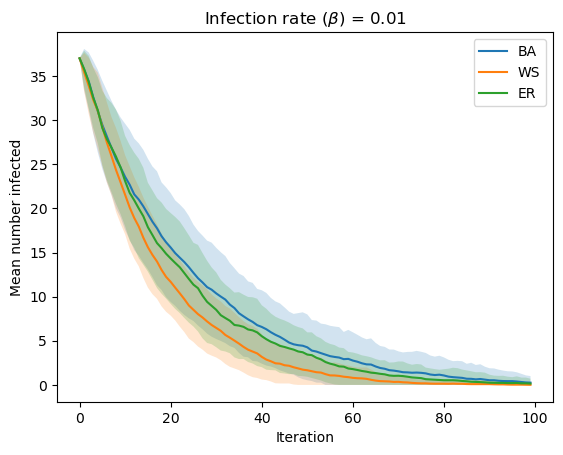

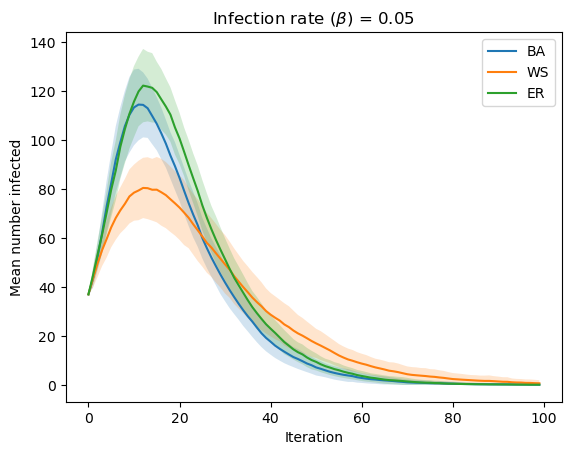

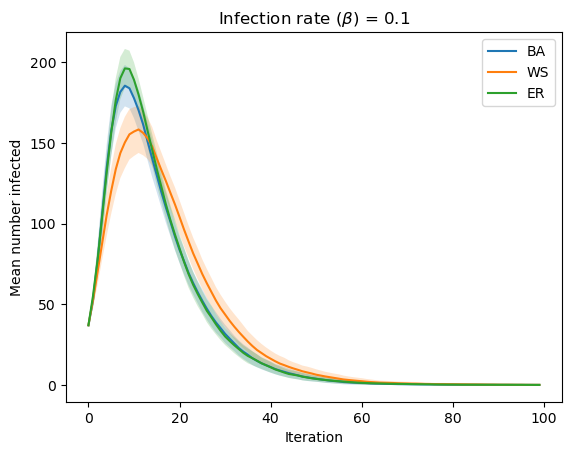

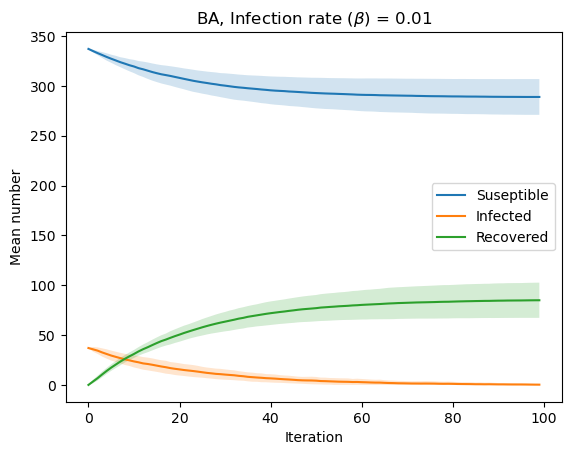

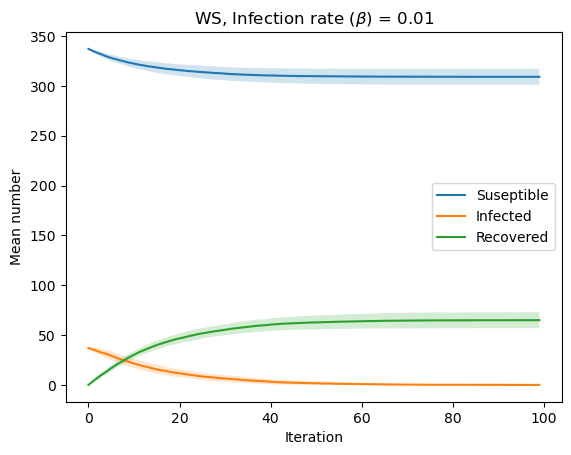

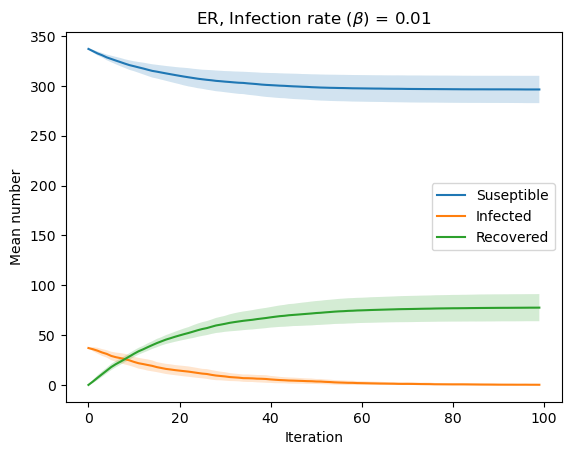

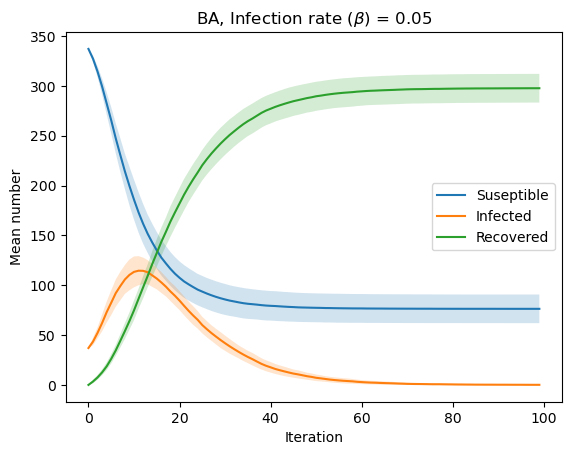

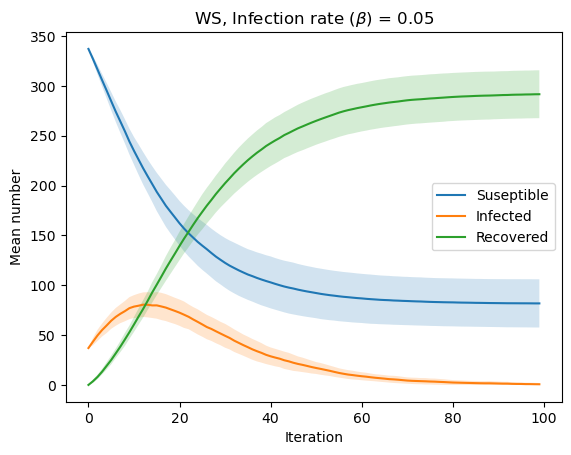

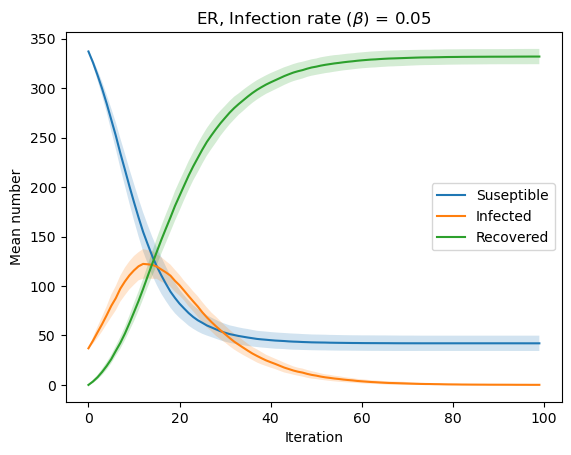

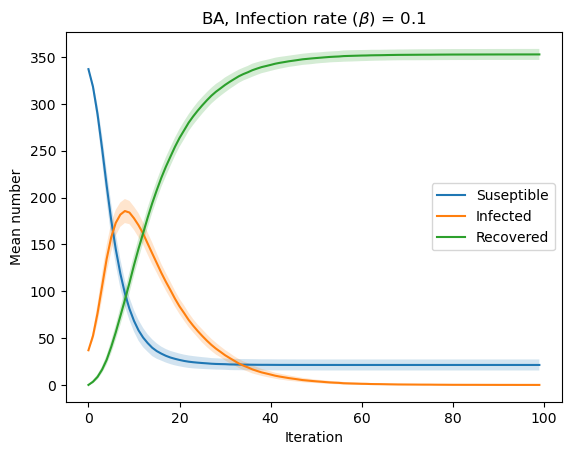

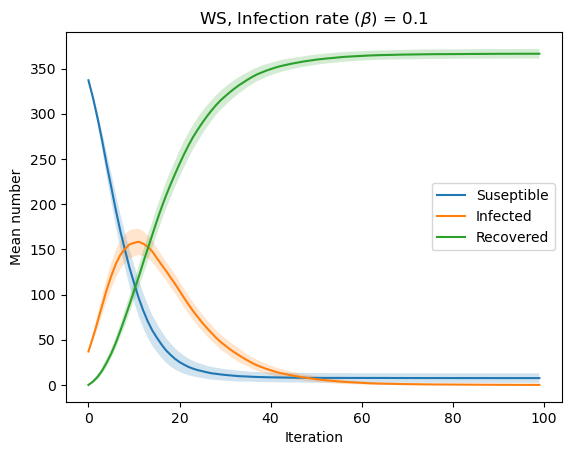

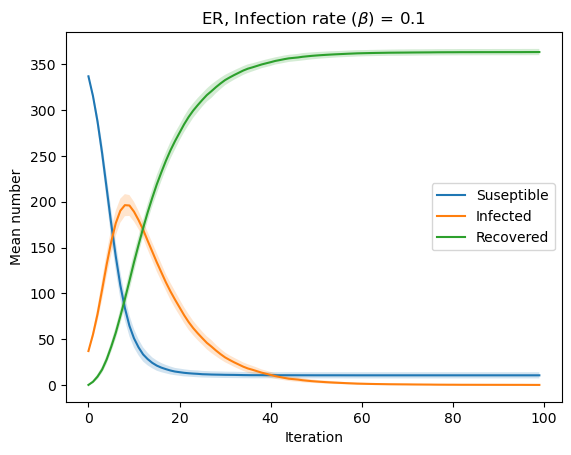

In [38]:
changing_beta= [0.01, 0.05, 0.10]
infected_fraction = 0.1
gamma = 0.1
nruns = 100
results_changing_beta = {}

for beta in changing_beta:
    results_changing_beta[beta] = {}
    for name, g in network.items():
        S_runs, I_runs, R_runs = repeat_sir(g, beta, gamma, runs = nruns, fraction_infected = infected_fraction)
        results_changing_beta[beta][name] = {'S' : S_runs, 'I' : I_runs, 'R' : R_runs}

#plotting mean number infected  
for beta in changing_beta:
    for name in network:
        I_runs = results_changing_beta[beta][name]['I']
        mean_I = np.mean(I_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        plt.plot(mean_I, label = name)
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)
    plt.xlabel('Iteration')
    plt.ylabel('Mean number infected')
    plt.title(rf'Infection rate ($\beta$) = {beta}')
    plt.legend()
    plt.show()

#plotting SIR
for beta in changing_beta:
    for name in network:
        S_runs = results_changing_beta[beta][name]['S']
        I_runs = results_changing_beta[beta][name]['I']
        R_runs = results_changing_beta[beta][name]['R']
        mean_S = np.mean(S_runs, axis=0)
        mean_I = np.mean(I_runs, axis=0)
        mean_R = np.mean(R_runs, axis=0)
        std_S = np.std(S_runs, axis=0)
        std_I = np.std(I_runs, axis=0)
        std_R = np.std(R_runs, axis=0)
        plt.plot(mean_S, label = 'Suseptible')
        plt.fill_between(np.arange(len(mean_S)), np.maximum(mean_S - std_S, 0), mean_S + std_S, alpha=0.2)
        plt.plot(mean_I, label = 'Infected')
        plt.fill_between(np.arange(len(mean_I)), np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2,)
        plt.plot(mean_R, label = 'Recovered')
        plt.fill_between(np.arange(len(mean_R)), np.maximum(mean_R - std_R, 0), mean_R + std_R, alpha=0.2)
        plt.xlabel('Iteration')
        plt.ylabel('Mean number')
        plt.title(rf'{name}, Infection rate ($\beta$) = {beta}')
        plt.legend()
        plt.show()


Load Socipatterns data 


In [39]:
import pandas as pd
import networkx as nx
import numpy as np
import ndlib.models.epidemics as ep
import ndlib.models.ModelConfig as mc
import matplotlib.pyplot as plt

adjacency_df = pd.read_csv('transmission_network.csv', sep=';', index_col=0)
adjacency_matrix = adjacency_df.to_numpy()
nodes = adjacency_df.index.to_list()

#create graph
g_social = nx.from_numpy_array(adjacency_matrix, edge_attr=None)

#replace integer node labels with original labels
g_social = nx.relabel_nodes(
    g_social,
    dict(enumerate(nodes))
)


Null strategy 

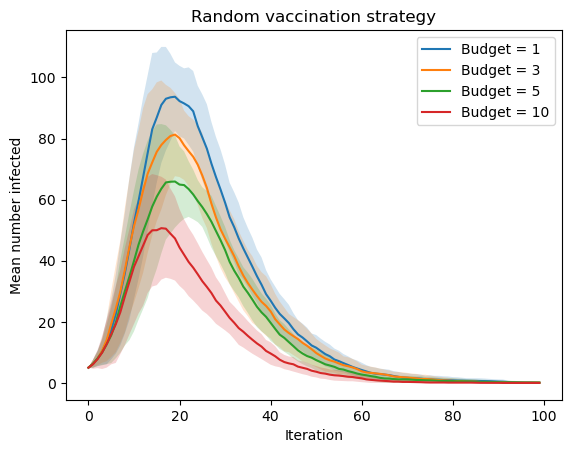

In [40]:
#one random vaccination simulation 
def random_vaccination(g, beta, gamma, vaccination_budget, iterations = 100, seed = None):

    #random number to decide intial infected 
    rng = np.random.default_rng(seed)

    #5 random individuals infected 
    initial_infected = rng.choice(list(g.nodes()), size=5, replace=False).tolist()

    #SIR model configuration 
    model = ep.SIRModel(g, seed = seed)
    config = mc.Configuration()
    config.add_model_parameter('beta', beta)
    config.add_model_parameter('gamma', gamma)
    config.add_model_initial_configuration('Infected', initial_infected)
    model.set_initial_status(config)

    #results 
    S = []
    I = []
    R = []
    vaccinated = set()

    #intial state 
    output = model.iteration()
    S.append(output['node_count'][0])
    I.append(output['node_count'][1])
    R.append(output['node_count'][2])


    #null vaccination campaign 
    for t in range(1, iterations):

        #unvaccinated nodes 
        possible_nodes = [node for node in g.nodes() if node not in vaccinated]

        #randomly choose nodes for vaccination
        selected_nodes = rng.choice(possible_nodes, size=min(vaccination_budget, len(possible_nodes)), replace = False).tolist()


        #only suseptible individuals change state after vaccination 
        for node in selected_nodes:
            if model.status[node] == 0:
                model.status[node] = 2
                vaccinated.add(node)


        #one step
        output = model.iteration()

        #results after step
        S.append(output['node_count'][0])
        I.append(output['node_count'][1])
        R.append(output['node_count'][2])

    return (np.array(S), np.array(I), np.array(R), len(vaccinated))

#function that repeats simulation 
def repeat_random_vaccination(g, beta, gamma, vaccination_budget, runs=30, iterations=100):
    S_runs = []
    I_runs = []
    R_runs = []
    vaccinated_runs = []

    for run in range(runs):
        S, I, R, vaccinated = random_vaccination(g, beta, gamma, vaccination_budget, iterations = iterations, seed = run)
       
        S_runs.append(S)
        I_runs.append(I)
        R_runs.append(R)
        vaccinated_runs.append(vaccinated)

    return (np.array(S_runs), np.array(I_runs), np.array(R_runs), np.array(vaccinated_runs))

#test for different vaccinaiton budgets 
vaccination_budgets = [1, 3, 5, 10]
beta = 0.05
gamma = 0.1
nruns = 30
results_random_vaccination = {}


for budget in vaccination_budgets:

    S_runs, I_runs, R_runs, vaccinated_runs = \
        repeat_random_vaccination(g_social, beta, gamma, vaccination_budget = budget, runs = nruns, iterations = 100)

    results_random_vaccination[budget] = {'S': S_runs, 'I': I_runs, 'R': R_runs, 'vaccinated': vaccinated_runs}

#plot for different vaccination budgets 
for budget in vaccination_budgets:

    I_runs = results_random_vaccination[budget]['I']
    mean_I = np.mean(I_runs, axis=0)
    std_I = np.std( I_runs, axis=0)
    x = np.arange(len(mean_I))
    line, = plt.plot(x, mean_I, label=f'Budget = {budget}')
    plt.fill_between(x, np.maximum(mean_I - std_I,0), mean_I + std_I, alpha=0.2)

plt.xlabel('Iteration')
plt.ylabel('Mean number infected')
plt.title('Random vaccination strategy')
plt.legend()
plt.show()

High degree targeted vaccination 


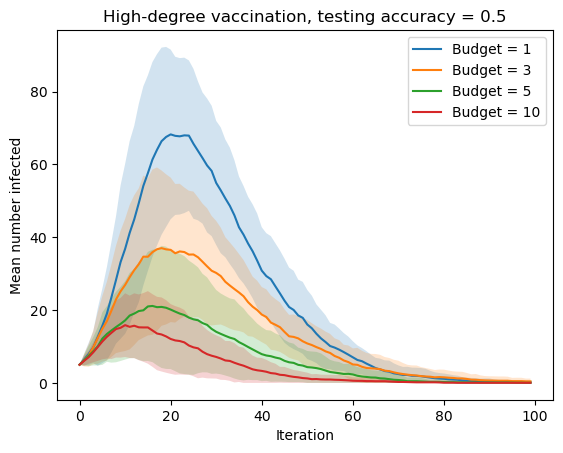

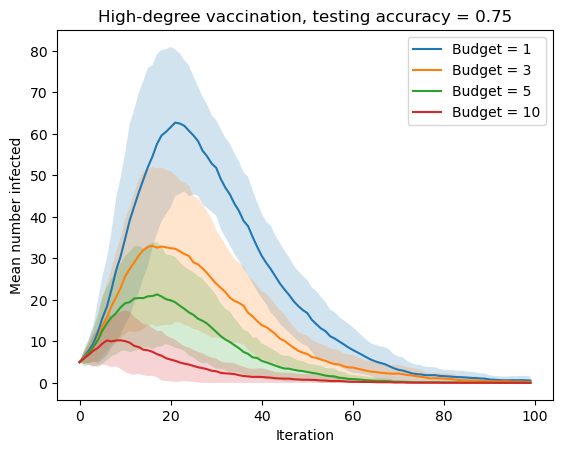

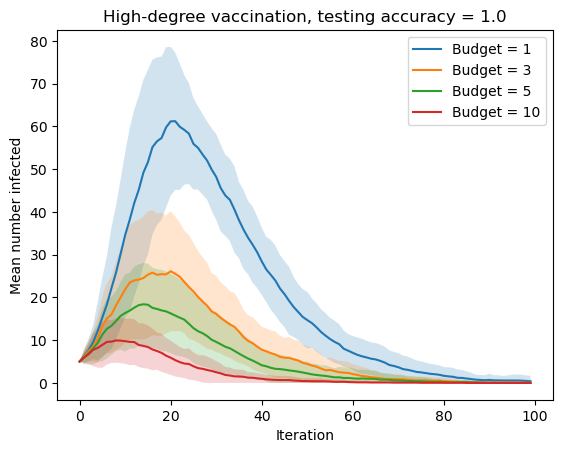

In [41]:
#test whether a node is susceptible
def test_node(model, node, testing_accuracy, rng):

    actually_susceptible = model.status[node] == 0
    
    #correct test
    if rng.random() < testing_accuracy:
        test_result = actually_susceptible

    #incorrect test
    else:
        test_result = not actually_susceptible

    return test_result

#one high degree vaccination simulation 
def high_degree_vaccination(g, beta, gamma, testing_budget, vaccination_budget, testing_accuracy, iterations = 100, seed = None):

    rng = np.random.default_rng(seed)

    #5 random initially infected individuals
    initial_infected = rng.choice(list(g.nodes()), size = 5, replace = False).tolist()

    #SIR model
    model = ep.SIRModel(g, seed = seed)

    config = mc.Configuration()
    config.add_model_parameter('beta', beta)
    config.add_model_parameter('gamma', gamma)
    config.add_model_initial_configuration('Infected', initial_infected)
    model.set_initial_status(config)

    #store results
    S = []
    I = []
    R = []
    vaccinated = set()


    #Rank nodes from highest degree to lowest degree
    degree_ranking = sorted(g.degree, key=lambda x: x[1], reverse=True)
    degree_ranking = [node for node, degree in degree_ranking]


    #initial state
    output = model.iteration()

    S.append(output['node_count'][0])
    I.append(output['node_count'][1])
    R.append(output['node_count'][2])


    #vaccination campaign
    for t in range(1, iterations):

        #nodes available for testing
        possible_nodes = [node for node in degree_ranking if node not in vaccinated]

        #testing higest degree nodes first
        tested_nodes = possible_nodes[:testing_budget]
        vaccines_used = 0

        for node in tested_nodes:

            #stop when vaccination budget is finshed 
            if vaccines_used >= vaccination_budget:
                break

            #test node 
            test_says_susceptible = test_node(model, node, testing_accuracy, rng)

            #vaccinate if test shows susceptibilty 
            if test_says_susceptible:
                vaccines_used += 1

                #change states 
                if model.status[node] == 0:
                    model.status[node] = 2
                    vaccinated.add(node)


        #one SIR iteration
        output = model.iteration()


        #store results
        S.append(output['node_count'][0])
        I.append(output['node_count'][1])
        R.append(output['node_count'][2])


    return (np.array(S), np.array(I), np.array(R), len(vaccinated))

#repeating high degree vaccination step
def repeat_high_degree_vaccination(g, beta, gamma, testing_budget, vaccination_budget, testing_accuracy, runs = 30, iterations = 100):
    S_runs = []
    I_runs = []
    R_runs = []
    vaccinated_runs = []

    for run in range(runs):
        S, I, R, vaccinated = high_degree_vaccination(g, beta, gamma, testing_budget, vaccination_budget, testing_accuracy, iterations = iterations, seed = run)
        S_runs.append(S)
        I_runs.append(I)
        R_runs.append(R)
        vaccinated_runs.append(vaccinated)

    return (np.array(S_runs), np.array(I_runs), np.array(R_runs), np.array(vaccinated_runs))

#running different vaccination budget and testing accuracies 
vaccination_budgets = [1, 3, 5, 10]
testing_accuracies = [0.5, 0.75, 1.0]
testing_budget = 20
beta = 0.05
gamma = 0.1
nruns = 30
results_high_degree = {}


for accuracy in testing_accuracies:
    results_high_degree[accuracy] = {}
    for budget in vaccination_budgets:
        S_runs, I_runs, R_runs, vaccinated_runs = \
            repeat_high_degree_vaccination(g_social, beta, gamma, testing_budget = testing_budget, vaccination_budget = budget, testing_accuracy = accuracy, runs = nruns, iterations = 100)

        results_high_degree[accuracy][budget] = {'S': S_runs, 'I': I_runs, 'R': R_runs, 'vaccinated': vaccinated_runs}

#plotting results
for accuracy in testing_accuracies:
    for budget in vaccination_budgets:
        I_runs = results_high_degree[accuracy][budget]['I']
        mean_I = np.mean(I_runs, axis = 0)
        std_I = np.std(I_runs, axis = 0)
        x = np.arange(len(mean_I))
        plt.plot(x, mean_I, label = f'Budget = {budget}')
        plt.fill_between(x, np.maximum(mean_I - std_I, 0), mean_I + std_I, alpha=0.2)

    plt.xlabel('Iteration')
    plt.ylabel('Mean number infected')
    plt.title(f'High-degree vaccination, 'f'testing accuracy = {accuracy}')
    plt.legend()
    plt.show()

In [42]:
def acquaintance_vaccination(g, beta, gamma, testing_budget, vaccination_budget,
                             testing_accuracy, iterations=100, seed=None):

    rng = np.random.default_rng(seed)

    # 5 random initially infected individuals
    initial_infected = rng.choice(
        list(g.nodes()), size=5, replace=False
    ).tolist()

    # SIR model
    model = ep.SIRModel(g, seed=seed)

    config = mc.Configuration()
    config.add_model_parameter('beta', beta)
    config.add_model_parameter('gamma', gamma)
    config.add_model_initial_configuration('Infected', initial_infected)
    model.set_initial_status(config)

    S = []
    I = []
    R = []
    vaccinated = set()

    # Initial state
    output = model.iteration()
    S.append(output['node_count'][0])
    I.append(output['node_count'][1])
    R.append(output['node_count'][2])

    # Vaccination campaign
    for t in range(1, iterations):

        tested_nodes = set()
        vaccines_used = 0
        tests_used = 0

        while tests_used < testing_budget and vaccines_used < vaccination_budget:

            # Choose a random node that has eligible neighbors
            possible_sources = [
                node for node in g.nodes()
                if any(
                    neighbor not in tested_nodes and neighbor not in vaccinated
                    for neighbor in g.neighbors(node)
                )
            ]

            if not possible_sources:
                break

            random_node = rng.choice(possible_sources)

            # Choose one of its neighbors at random
            possible_neighbors = [
                node for node in g.neighbors(random_node)
                if node not in tested_nodes and node not in vaccinated
            ]

            selected_node = rng.choice(possible_neighbors)
            tested_nodes.add(selected_node)

            # Test the selected neighbor
            tests_used += 1
            test_says_susceptible = test_node(
                model, selected_node, testing_accuracy, rng
            )

            if test_says_susceptible:
                vaccines_used += 1

                if model.status[selected_node] == 0:
                    model.status[selected_node] = 2
                    vaccinated.add(selected_node)

        # One SIR iteration
        output = model.iteration()

        S.append(output['node_count'][0])
        I.append(output['node_count'][1])
        R.append(output['node_count'][2])

    return (
        np.array(S),
        np.array(I),
        np.array(R),
        len(vaccinated)
    )

In [43]:
def repeat_acquaintance_vaccination(g, beta, gamma, testing_budget,
                                   vaccination_budget, testing_accuracy,
                                   runs=30, iterations=100):

    S_runs = []
    I_runs = []
    R_runs = []
    vaccinated_runs = []

    for run in range(runs):
        S, I, R, vaccinated = acquaintance_vaccination(
            g, beta, gamma, testing_budget,
            vaccination_budget, testing_accuracy,
            iterations=iterations, seed=run
        )

        S_runs.append(S)
        I_runs.append(I)
        R_runs.append(R)
        vaccinated_runs.append(vaccinated)

    return (
        np.array(S_runs),
        np.array(I_runs),
        np.array(R_runs),
        np.array(vaccinated_runs)
    )

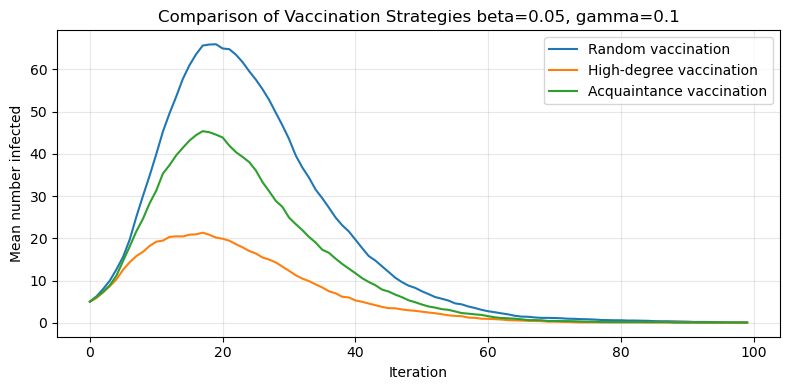

In [45]:
beta = 0.05
gamma = 0.1

testing_budget = 20
vaccination_budget = 5
testing_accuracy = 0.75

nruns = 30
iterations = 100

S_runs, I_runs, R_runs, vaccinated_runs = repeat_acquaintance_vaccination(
    g_social, beta, gamma,
    testing_budget, vaccination_budget, testing_accuracy,
    runs=nruns, iterations=iterations
)

# Previously calculated results
I_random = results_random_vaccination[vaccination_budget]['I']
I_high_degree = results_high_degree[testing_accuracy][vaccination_budget]['I']

plt.figure(figsize=(8, 4))

plt.plot(np.mean(I_random, axis=0), label="Random vaccination")
plt.plot(np.mean(I_high_degree, axis=0), label="High-degree vaccination")
plt.plot(np.mean(I_runs, axis=0), label="Acquaintance vaccination")

plt.xlabel("Iteration")
plt.ylabel("Mean number infected")
plt.title("Comparison of Vaccination Strategies beta=0.05, gamma=0.1", fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()